[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# A long holdings list can still have a concentrated head

How much of the positive reported weight sits in the largest positions? We compare two bounded fund partitions, inspect missing and signed weights, and build cumulative concentration curves in SQL. The final experiment changes the number of leading positions retained.

**Current public data:** [QYLD](https://www.globalxetfs.com/funds/qyld/) and [XYLD](https://www.globalxetfs.com/funds/xyld/) are chosen as two concrete examples from Global X’s lineup. This is a description of their published holdings rows, not a recommendation or a risk ranking. The source files change over time; the notebook records their own publication dates and the retrieval time. It has no historical as-of input and no replay fallback.

## Choose the head of the distribution

`TOP_N` is an integer from 5 to 30. Default **10** summarizes the ten largest positive-weight rows in each fund; the experiment uses **20**. It changes the local rank cutoff, not the funds retrieved. Restart and run all after editing. The two requested funds remain explicit in SQL so the worker never performs an unbounded all-fund holdings scan.

In [1]:
TOP_N = 10  # positive-weight rows per fund, 5–30; experiment: 20

In [2]:
from datetime import UTC, datetime

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from notebook_support import COLORS, finish, prose, theme

if type(TOP_N) is not int or not 5 <= TOP_N <= 30:
    raise ValueError("TOP_N must be an integer from 5 through 30.")
retrieved_utc = datetime.now(UTC).isoformat(timespec="seconds")
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-globalx/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-globalx/notebooks/pyproject.toml.

## Attach the pinned native release

The literal release location downloads the platform binary and verifies its published checksum. The notebook needs no local Bun installation or worker build. This native worker reads the issuer’s website directly; it does not offer a fixture endpoint override. All holdings calls below are materialized before local SELECT capture and plotting.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'globalx' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-etf-globalx@v0.4.0');
CREATE TABLE requested_funds AS SELECT * FROM (VALUES ('QYLD'), ('XYLD')) AS t(fund_ticker);

,Count


## Fetch only the two selected partitions

`fund_ticker` selects the fund; `ticker` on a holdings row identifies the constituent and can be NULL. The source weights are **percentage points**: `7.5` means 7.5%, not 750%. The product catalog is used for labels and its separately dated fund metadata. It is not a replacement for each holdings file’s own date.

In [4]:
%%sql
CREATE TABLE products AS
SELECT ticker, fund_name, as_of_date AS product_date
FROM globalx.main.products WHERE ticker IN ('QYLD', 'XYLD');
CREATE TABLE holdings AS
SELECT * FROM globalx.main.holdings WHERE fund_ticker IN ('QYLD', 'XYLD');
CREATE TABLE availability AS
SELECT r.fund_ticker, p.fund_name, p.product_date,
       count(h.fund_ticker) AS reported_rows, count(h.weight_percent) AS known_weights,
       count(h.fund_ticker) FILTER (WHERE h.weight_percent IS NULL) AS missing_weights,
       count(*) FILTER (WHERE h.weight_percent > 0) AS positive_rows,
       count(*) FILTER (WHERE h.weight_percent = 0) AS zero_rows,
       count(*) FILTER (WHERE h.weight_percent < 0) AS negative_rows,
       count(DISTINCT h.as_of_date) AS holdings_dates,
       min(h.as_of_date) AS holdings_date,
       sum(h.weight_percent) AS net_weight_percent,
       sum(h.weight_percent) FILTER (WHERE h.weight_percent > 0) AS positive_weight_percent,
       sum(h.weight_percent) FILTER (WHERE h.weight_percent < 0) AS negative_weight_percent
FROM requested_funds r LEFT JOIN products p ON p.ticker = r.fund_ticker
LEFT JOIN holdings h USING (fund_ticker)
GROUP BY r.fund_ticker, p.fund_name, p.product_date;

,Count


In [5]:
%%sql availability <<
SELECT * FROM availability ORDER BY fund_ticker;

In [6]:
display(availability.round(4))

,fund_ticker,fund_name,product_date,reported_rows,known_weights,missing_weights,positive_rows,zero_rows,negative_rows,holdings_dates,holdings_date,net_weight_percent,positive_weight_percent,negative_weight_percent
0,QYLD,Nasdaq 100® Covered Call ETF,2026-11-13,104,104,0,103,0,1,1,2026-11-13,100.00,100.02,-0.02
1,XYLD,S&P 500® Covered Call ETF,2026-11-13,507,507,0,505,1,1,1,2026-11-13,100.06,100.13,-0.07


In [7]:
prose(
    f"Retrieval started at **{retrieved_utc}**. The catalog and holdings files are separate "
    "requests, not an atomic issuer snapshot. The displayed `holdings_date` belongs to each file; "
    "matching dates do not establish simultaneous pricing. Small differences between net weight "
    "and 100% can reflect published rounding. We retain those sums without forcing them to 100."
)

Retrieval started at **2026-11-14T06:25:51+00:00**. The catalog and holdings files are separate requests, not an atomic issuer snapshot. The displayed `holdings_date` belongs to each file; matching dates do not establish simultaneous pricing. Small differences between net weight and 100% can reflect published rounding. We retain those sums without forcing them to 100.

## Establish a usable denominator

A missing or empty fund must not become a zero-concentration observation. Before calculating shares, require a labeled product, one dated nonempty holdings file, complete finite weights and enough positive rows. Keep negative and zero rows in the availability diagnostics. The key check uses `(fund_ticker, name, sedol)`, the worker’s documented row grain; it does not merge multiple securities of the same issuer.

In [8]:
%%sql source_checks <<
SELECT 'both requested funds are labeled and populated' AS check_name,
       count(*) = 2 AND bool_and(fund_name IS NOT NULL AND reported_rows > 0) AS passed FROM availability
UNION ALL SELECT 'complete finite weights',
    (SELECT bool_and(missing_weights = 0) FROM availability) AND
    (SELECT bool_and(isfinite(weight_percent)) FROM holdings)
UNION ALL SELECT 'one dated file per fund', bool_and(holdings_dates = 1 AND holdings_date IS NOT NULL) FROM availability
UNION ALL SELECT 'positive denominator and enough rows',
    bool_and(positive_weight_percent > 0 AND positive_rows >= {{TOP_N}}) FROM availability
UNION ALL SELECT 'unique holdings row keys', count(*) = count(DISTINCT (fund_ticker, name, sedol)) FROM holdings
UNION ALL SELECT 'signed decomposition agrees',
    bool_and(abs(net_weight_percent - positive_weight_percent - coalesce(negative_weight_percent, 0)) < 1e-8) FROM availability;

In [9]:
display(source_checks)
assert source_checks.passed.fillna(False).all(), (
    "A required fund file is missing or its weights cannot support the comparison."
)

,check_name,passed
0,both requested funds are labeled and populated,True
1,complete finite weights,True
2,one dated file per fund,True
3,positive denominator and enough rows,True
4,unique holdings row keys,True
5,signed decomposition agrees,True


## Rank and normalize the positive rows

The denominator is the **sum of positive reported weights within each fund**. Each row’s share is its positive weight divided by that sum; the shares sum to 100% within this explicitly restricted set. These are not net-asset weights after normalization. Negative and zero weights are outside this concentration calculation, and a rounded zero may represent a small nonzero position. No constituent is classified from its ticker alone.

A deterministic secondary order resolves equal published weights. The displayed top-N set can split a tie; because tied weights are equal, the cumulative share at N is unaffected by their ordering.

In [10]:
%%sql
CREATE TABLE ranked AS
WITH positive AS (
    SELECT h.*, row_number() OVER (
        PARTITION BY fund_ticker ORDER BY weight_percent DESC, name, sedol
    ) AS position,
    100.0 * weight_percent / sum(weight_percent) OVER (PARTITION BY fund_ticker) AS positive_share_percent
    FROM holdings h WHERE weight_percent > 0
)
SELECT *, sum(positive_share_percent) OVER (
    PARTITION BY fund_ticker ORDER BY position ROWS UNBOUNDED PRECEDING
) AS cumulative_share_percent
FROM positive;
CREATE TABLE summary AS
SELECT fund_ticker, min(as_of_date) AS holdings_date, count(*) AS positive_rows,
       sum(positive_share_percent) FILTER (WHERE position <= {{TOP_N}}) AS top_n_share_percent,
       min(position) FILTER (WHERE cumulative_share_percent >= 50) AS positions_to_half
FROM ranked GROUP BY fund_ticker;

,Count


In [11]:
%%sql summary <<
SELECT s.*, a.reported_rows, a.net_weight_percent, a.negative_rows
FROM summary s JOIN availability a USING (fund_ticker) ORDER BY fund_ticker;

In [12]:
display(summary.round(3))

,fund_ticker,holdings_date,positive_rows,top_n_share_percent,positions_to_half,reported_rows,net_weight_percent,negative_rows
0,QYLD,2026-11-13,103,46.511,12,104,100.00,1
1,XYLD,2026-11-13,505,36.932,23,507,100.06,1


In [13]:
%%sql curve <<
SELECT fund_ticker, position, positive_share_percent, cumulative_share_percent,
       name, ticker, sedol, weight_percent, as_of_date
FROM ranked ORDER BY fund_ticker, position;

## Read concentration at the same rank

Both curves share the same rank and percentage scales. The chart shows the first 50 positive rows; the denominator still includes all positive rows in each fund. The vertical line selects the requested top-N cutoff. A steeper curve means more of this positive-weight total sits near the head of the published list, not necessarily greater portfolio risk.

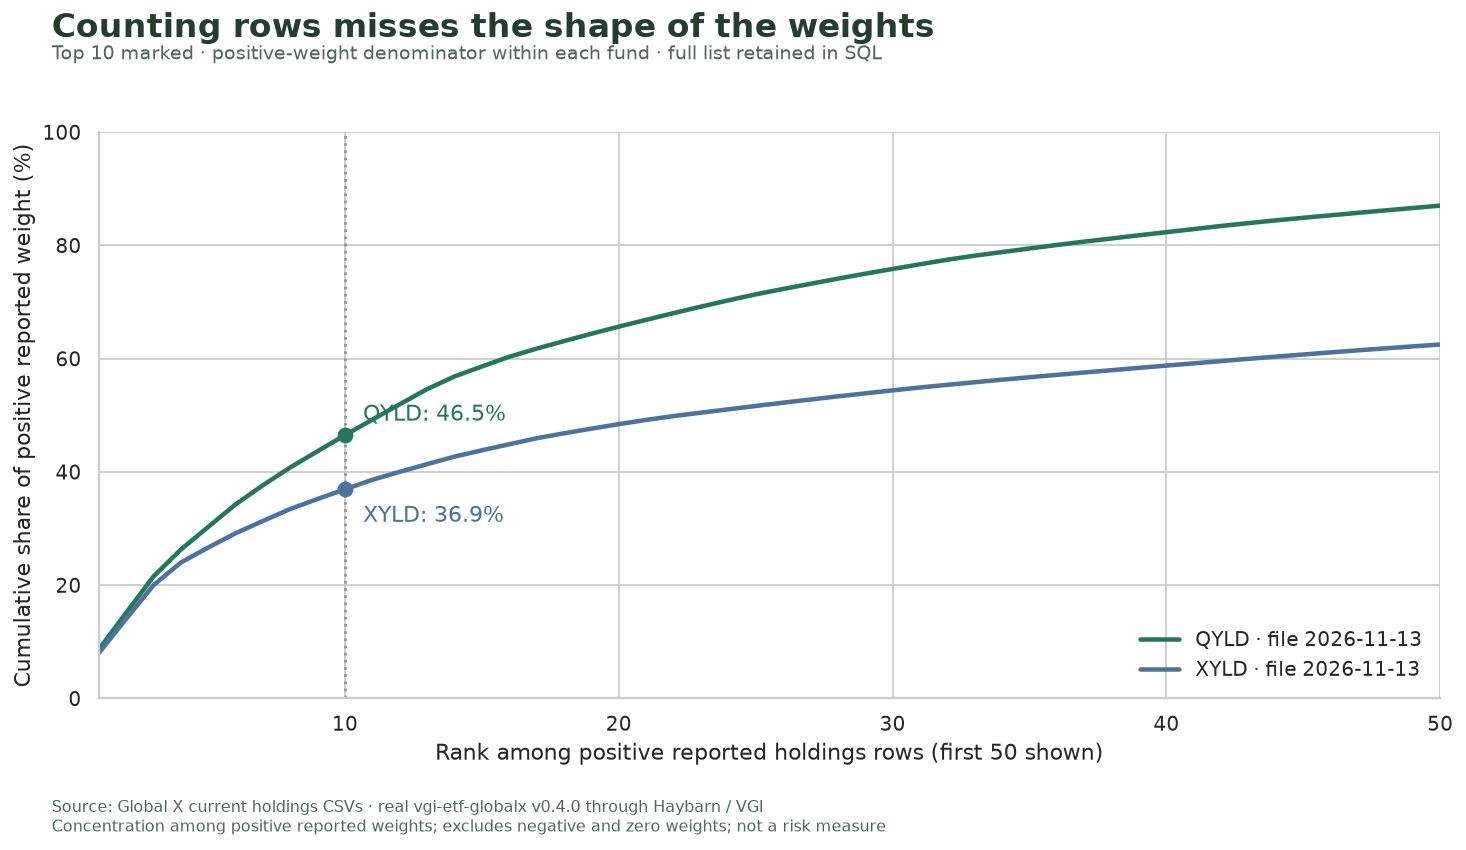

In [14]:
fig, ax = plt.subplots(figsize=(12, 6.6))
for fund, group in curve.groupby("fund_ticker", sort=True):
    visible = group.loc[group.position <= 50]
    row = summary.loc[summary.fund_ticker == fund].iloc[0]
    ax.plot(
        visible.position,
        visible.cumulative_share_percent,
        color=COLORS[fund],
        linewidth=2.5,
        label=f"{fund} · file {row.holdings_date:%Y-%m-%d}",
    )
    point = group.loc[group.position == TOP_N].iloc[0]
    ax.scatter([TOP_N], [point.cumulative_share_percent], color=COLORS[fund], s=60, zorder=4)
    ax.annotate(
        f"{fund}: {point.cumulative_share_percent:.1f}%",
        (TOP_N, point.cumulative_share_percent),
        xytext=(10, 8 if fund == "QYLD" else -18),
        textcoords="offset points",
        color=COLORS[fund],
    )
ax.axvline(TOP_N, color="#8b9690", linestyle=":", linewidth=1.5)
ax.set_xlim(1, 50)
ax.set_ylim(0, 100)
ax.set_xlabel("Rank among positive reported holdings rows (first 50 shown)")
ax.set_ylabel("Cumulative share of positive reported weight (%)")
ax.legend(loc="lower right", frameon=False)
fig.subplots_adjust(left=0.10, right=0.96, bottom=0.18, top=0.84)
finish(
    fig,
    "Counting rows misses the shape of the weights",
    f"Top {TOP_N} marked · positive-weight denominator within each fund · full list retained in SQL",
    f"concentration-top-{TOP_N}.png",
)

In [15]:
sentences = []
for row in summary.itertuples():
    sentences.append(
        f"**{row.fund_ticker}** reports **{int(row.reported_rows)} rows**, of which "
        f"**{int(row.positive_rows)}** have positive weight. Its largest **{TOP_N}** rows "
        f"hold **{row.top_n_share_percent:.1f}%** of that positive total; "
        f"**{int(row.positions_to_half)} rows** reach half."
    )
prose(
    " ".join(sentences) + " The normalization is deliberately restricted to positive rows. "
    "It does not measure option notional exposure, delta, correlations, expected return or a fund’s suitability."
)

**QYLD** reports **104 rows**, of which **103** have positive weight. Its largest **10** rows hold **46.5%** of that positive total; **12 rows** reach half. **XYLD** reports **507 rows**, of which **505** have positive weight. Its largest **10** rows hold **36.9%** of that positive total; **23 rows** reach half. The normalization is deliberately restricted to positive rows. It does not measure option notional exposure, delta, correlations, expected return or a fund’s suitability.

## Inspect the rows behind the head

Each bar shows a row’s share of the same positive-weight denominator. Names and constituent tickers make the contributors inspectable. Distinct share classes remain distinct rows; these are security-level entries, not a count of unique issuers. The shared horizontal scale lets the two panels use the same unit.

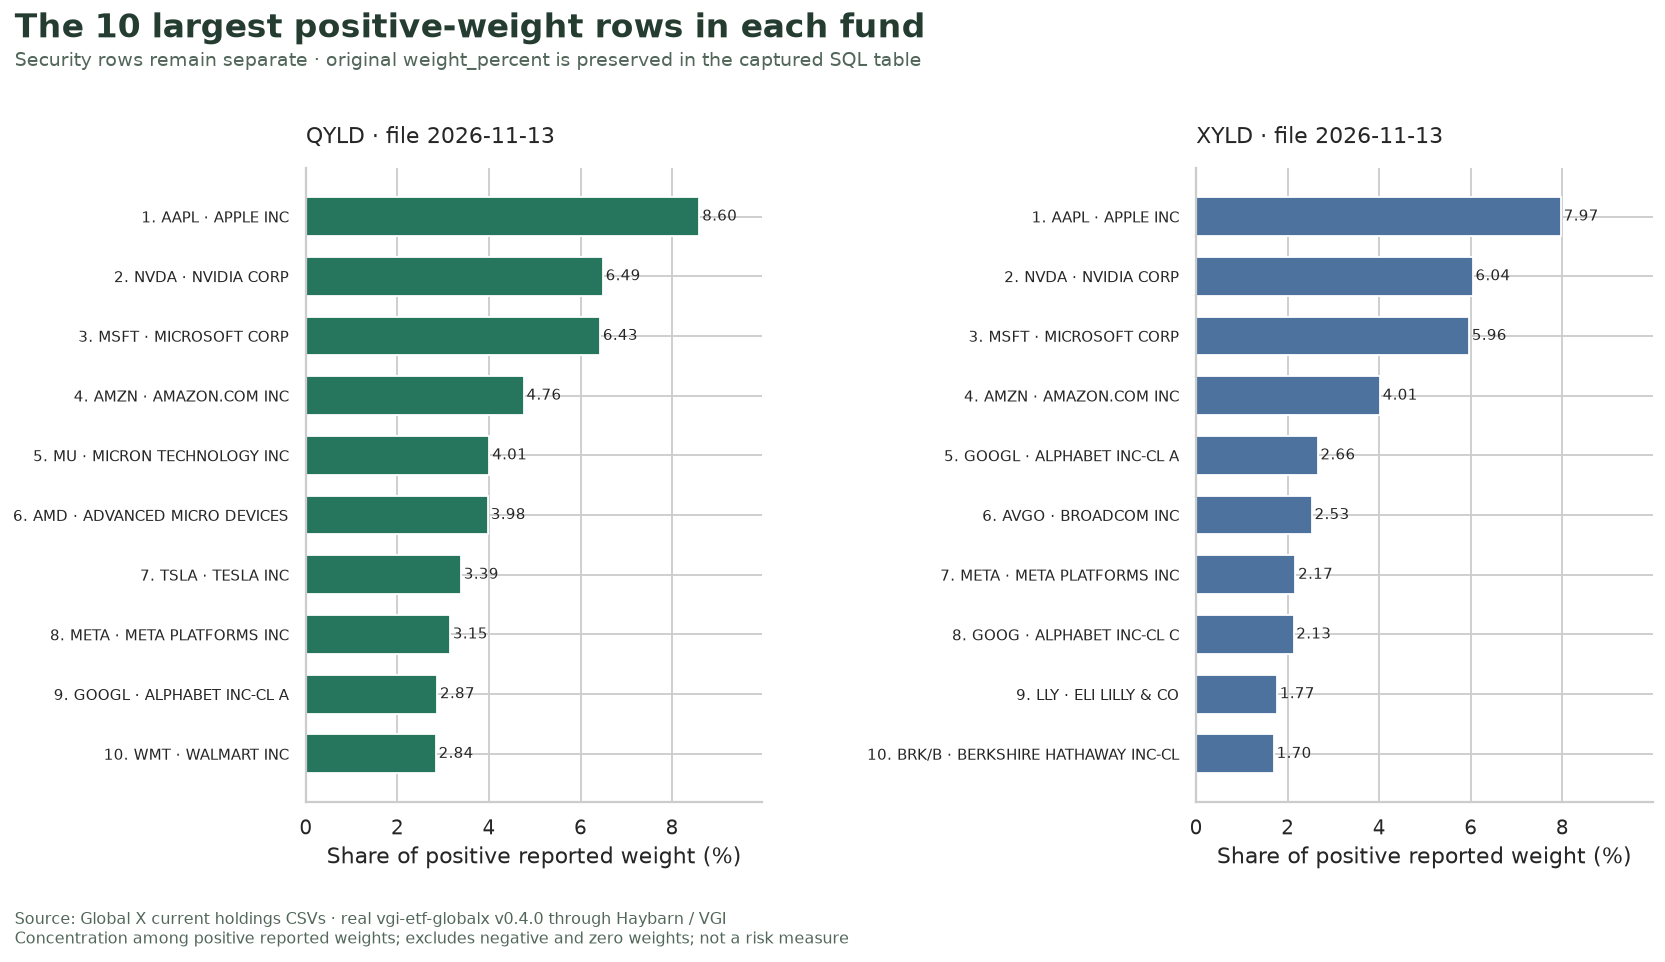

In [16]:
top = curve.loc[curve.position <= TOP_N].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, max(7.5, 0.30 * TOP_N + 3.2)), sharex=True)
for ax, fund in zip(axes, sorted(COLORS), strict=True):
    group = top.loc[top.fund_ticker == fund].reset_index(drop=True)
    labels = [
        f"{int(row.position)}. {row.ticker if pd.notna(row.ticker) else '—'} · {row['name'][:25]}"
        for _, row in group.iterrows()
    ]
    ax.barh(np.arange(len(group)), group.positive_share_percent, color=COLORS[fund], height=0.65)
    for i, value in enumerate(group.positive_share_percent):
        ax.text(value + 0.06, i, f"{value:.2f}", va="center", fontsize=8.5)
    ax.set_yticks(np.arange(len(group)), labels, fontsize=8.5)
    ax.invert_yaxis()
    date = summary.loc[summary.fund_ticker == fund, "holdings_date"].iloc[0]
    ax.set_title(f"{fund} · file {date:%Y-%m-%d}", loc="left", fontsize=12, pad=14)
    ax.set_xlabel("Share of positive reported weight (%)")
    ax.set_xlim(0, top.positive_share_percent.max() * 1.16)
fig.subplots_adjust(left=0.23, right=0.97, bottom=0.17, top=0.82, wspace=0.95)
finish(
    fig,
    f"The {TOP_N} largest positive-weight rows in each fund",
    "Security rows remain separate · original weight_percent is preserved in the captured SQL table",
    f"contributors-top-{TOP_N}.png",
)

## Check the cumulative arithmetic

The normalized shares must sum to 100%, the cumulative curve must never fall, and the top-N share must equal the curve at rank N. These checks remain valid as the issuer changes its current files or the rank cutoff changes.

In [17]:
%%sql arithmetic_checks <<
SELECT 'positive shares total 100 percent' AS check_name, bool_and(abs(total - 100) < 1e-8) AS passed
FROM (SELECT fund_ticker, sum(positive_share_percent) AS total FROM ranked GROUP BY fund_ticker)
UNION ALL SELECT 'cumulative curves are monotone', bool_and(cumulative_share_percent >= previous)
FROM (SELECT *, lag(cumulative_share_percent, 1, 0) OVER (PARTITION BY fund_ticker ORDER BY position) AS previous FROM ranked)
UNION ALL SELECT 'top N agrees with curve', bool_and(abs(s.top_n_share_percent - r.cumulative_share_percent) < 1e-8)
FROM summary s JOIN ranked r USING (fund_ticker) WHERE position = {{TOP_N}};

In [18]:
display(arithmetic_checks)
assert arithmetic_checks.passed.fillna(False).all(), "Concentration arithmetic failed."
prose(
    f"All **{len(source_checks) + len(arithmetic_checks)} source and arithmetic checks** pass. "
    "The source retains signed net weights, while the charts answer the narrower "
    "positive-weight concentration question."
)

,check_name,passed
0,positive shares total 100 percent,True
1,cumulative curves are monotone,True
2,top N agrees with curve,True


All **9 source and arithmetic checks** pass. The source retains signed net weights, while the charts answer the narrower positive-weight concentration question.

## Experiment: expand the head from 10 to 20 rows

Change only `TOP_N` from **10 to 20**, restart and run all. For an unchanged source snapshot, the cumulative share cannot fall when ten more positive rows are included. Compare the top-N shares and added contributors; the full positive-row count and positions-to-half should stay the same. Restore **10** for the default.

Each fresh kernel retrieves **current** files again. Compare file dates before attributing differences solely to the rank cutoff; even equal dates can contain an issuer revision. The README provides a separate-output command. These descriptive concentration measures do not capture the complete economics of covered-call portfolios or establish investment suitability.

In [19]:
connection.close()

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · Source: [Global X ETFs](https://www.globalxetfs.com/explore)